# 09 Ablation studies

Each ablation changes **one** part of the selected temporal model and keeps everything else fixed (same
hyperparameters, same split, same early stopping). Every variant is trained with three seeds, so a
difference only counts if it is larger than the seed-to-seed spread.

| Question | Variant |
|---|---|
| Does the GRU branch help? | no GRU (= embedding MLP) |
| How much history should the GRU read? | 7 or 28 days instead of 14 |
| Do learned embeddings help? | one-hot categories; no categories at all |
| Can the GRU replace the hand-made history features? | drop the 19 Phase 1 history features, with and without GRU |
| What does each regulariser do? | no dropout; no weight decay; no early stopping (40 epochs) |

In [1]:
import copy
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, log_loss

plt.rcParams.update({"font.size": 7, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from pathlib import Path

ROOT = Path("..").resolve()
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"

SEEDS = (42, 43, 44)
torch.set_num_threads(4)

In [3]:
data = np.load(PROCESSED_DIR / "dl_inputs.npz")
with open(PROCESSED_DIR / "dl_preprocessing.json") as f:
    prep = json.load(f)
with open(RESULTS_DIR / "dl_selected.json") as f:
    selected = json.load(f)

DAILY = torch.tensor(data["daily"])
MAX_SEQ_LEN = prep["max_seq_len"]
CARDS = [len(prep["vocab"][c]) + 1 for c in prep["cat_cols"]]
HISTORY_IDX = prep["history_idx"]


def load_split(s):
    return {"num": torch.tensor(data[f"{s}_num"]), "cat": torch.tensor(data[f"{s}_cat"]),
            "day": torch.tensor(data[f"{s}_day"]), "org": torch.tensor(data[f"{s}_seq_origin"]),
            "y": torch.tensor(data[f"{s}_y"])}


train, val, test = (load_split(s) for s in ("train", "val", "test"))
TRAIN_RATE = float(train["y"].mean())
BASE = {k: v for k, v in selected["Temporal"].items() if k not in ("params", "best_epoch")}
BASE["hidden"] = tuple(BASE["hidden"])
BASE

{'hidden': (64, 32),
 'dropout': 0.3,
 'weight_decay': 0.0001,
 'lr': 0.001,
 'seq_len': 14,
 'gru_hidden': 16}

Same network and training code as notebook 07, with one extra option `cat_mode="none"` (no categorical
inputs) and an `early_stopping` switch.

In [4]:
def emb_dim(n):
    return min(10, round(1.6 * n ** 0.56))


class DelayNet(nn.Module):
    def __init__(self, n_num, cards, hidden=(128, 64), dropout=0.2, seq_len=0, gru_hidden=16,
                 cat_mode="embedding", daily=None):
        super().__init__()
        self.cards, self.cat_mode, self.seq_len = cards, cat_mode, seq_len
        if cat_mode == "embedding":
            self.embs = nn.ModuleList(nn.Embedding(n, emb_dim(n), padding_idx=0) for n in cards)
            width = n_num + sum(emb_dim(n) for n in cards)
        elif cat_mode == "onehot":
            width = n_num + sum(cards)
        else:
            width = n_num
        if seq_len:
            self.register_buffer("daily", daily)
            self.gru = nn.GRU(daily.shape[-1], gru_hidden, batch_first=True)
            width += gru_hidden
        layers = []
        for h in hidden:
            layers += [nn.Linear(width, h), nn.ReLU(), nn.Dropout(dropout)]
            width = h
        layers.append(nn.Linear(width, 1))
        self.mlp = nn.Sequential(*layers)

    def history(self, cat, day, org):
        steps = day[:, None] + MAX_SEQ_LEN - self.seq_len + torch.arange(self.seq_len)
        return self.daily[org[:, None], cat[:, :1], steps]

    def forward(self, num, cat, day, org):
        parts = [num]
        if self.cat_mode == "embedding":
            parts += [emb(cat[:, i]) for i, emb in enumerate(self.embs)]
        elif self.cat_mode == "onehot":
            parts += [F.one_hot(cat[:, i], n).float() for i, n in enumerate(self.cards)]
        if self.seq_len:
            _, h = self.gru(self.history(cat, day, org))
            parts.append(h[-1])
        return self.mlp(torch.cat(parts, dim=1)).squeeze(1)


def batch_inputs(t, idx=slice(None)):
    return t["num"][idx], t["cat"][idx], t["day"][idx], t["org"][idx]


def predict(model, t, batch_size=8192):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(t["y"]), batch_size):
            out.append(torch.sigmoid(model(*batch_inputs(t, slice(i, i + batch_size)))))
    return torch.cat(out).numpy()


def train_model(cfg, tr, va, seed, max_epochs=40, patience=4, batch_size=1024, early_stopping=True):
    torch.manual_seed(seed)
    model = DelayNet(tr["num"].shape[1], CARDS, hidden=cfg["hidden"], dropout=cfg["dropout"],
                     seq_len=cfg["seq_len"], gru_hidden=cfg.get("gru_hidden", 16),
                     cat_mode=cfg.get("cat_mode", "embedding"), daily=DAILY)
    with torch.no_grad():
        model.mlp[-1].bias.fill_(np.log(TRAIN_RATE / (1 - TRAIN_RATE)))
    decay = [p for n, p in model.named_parameters() if p.ndim > 1]
    no_decay = [p for n, p in model.named_parameters() if p.ndim <= 1]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                             {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])
    gen = torch.Generator().manual_seed(seed)
    y_val = va["y"].numpy()
    best_ap, best_state, best_epoch, bad = -1, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(tr["y"]), generator=gen)
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            loss = F.binary_cross_entropy_with_logits(model(*batch_inputs(tr, idx)), tr["y"][idx])
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        ap = average_precision_score(y_val, predict(model, va))
        if ap > best_ap:
            best_ap, best_state, best_epoch, bad = ap, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            bad += 1
            if early_stopping and bad >= patience:
                break
    if early_stopping:
        model.load_state_dict(best_state)
    else:
        best_epoch = epoch
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return model, best_epoch, params

## Variants

In [5]:
def drop_history(t):
    keep = [i for i in range(t["num"].shape[1]) if i not in HISTORY_IDX]
    return {**t, "num": t["num"][:, keep]}


no_hist = {s: drop_history(t) for s, t in (("train", train), ("val", val), ("test", test))}
full = {"train": train, "val": val, "test": test}

VARIANTS = [
    ("Selected temporal model", BASE, full, True),
    ("No GRU (embedding MLP)", {**BASE, "seq_len": 0}, full, True),
    ("GRU reads 7 days", {**BASE, "seq_len": 7}, full, True),
    ("GRU reads 28 days", {**BASE, "seq_len": 28}, full, True),
    ("One-hot instead of embeddings", {**BASE, "cat_mode": "onehot"}, full, True),
    ("No carrier/origin/dest input", {**BASE, "cat_mode": "none"}, full, True),
    ("No Phase 1 history features", BASE, no_hist, True),
    ("No history features, no GRU", {**BASE, "seq_len": 0}, no_hist, True),
    ("No dropout", {**BASE, "dropout": 0.0}, full, True),
    ("No weight decay", {**BASE, "weight_decay": 0.0}, full, True),
    ("No early stopping (40 epochs)", BASE, full, False),
]

rows = []
start = time.time()
for name, cfg, d, es in VARIANTS:
    for seed in SEEDS:
        model, epoch, params = train_model(cfg, d["train"], d["val"], seed, early_stopping=es)
        rows.append({"variant": name, "seed": seed, "epochs": epoch, "params": params,
                     "val_pr_auc": average_precision_score(d["val"]["y"].numpy(), predict(model, d["val"])),
                     "test_pr_auc": average_precision_score(d["test"]["y"].numpy(), predict(model, d["test"]))})
print(f"{len(rows)} runs in {time.time() - start:.0f} s")
runs = pd.DataFrame(rows)
runs.to_csv(RESULTS_DIR / "ablation_runs.csv", index=False)

33 runs in 335 s


In [6]:
order = [v[0] for v in VARIANTS]
summary = (runs.groupby("variant", sort=False)
           .agg(params=("params", "first"), epochs=("epochs", "mean"),
                val_mean=("val_pr_auc", "mean"), val_std=("val_pr_auc", "std"),
                test_mean=("test_pr_auc", "mean"), test_std=("test_pr_auc", "std"))
           .loc[order])
ref = summary.loc["Selected temporal model"]
summary["val_change"] = summary["val_mean"] - ref["val_mean"]
summary["test_change"] = summary["test_mean"] - ref["test_mean"]
summary.to_csv(RESULTS_DIR / "ablation_summary.csv")
summary.round(4)

,params,epochs,val_mean,val_std,test_mean,test_std,val_change,test_change
variant,,,,,,,,
Selected temporal model,9125,2.6667,0.2936,0.0039,0.4993,0.0099,0.0000,0.0000
No GRU (embedding MLP),6757,4.6667,0.2914,0.0021,0.4969,0.0010,-0.0021,-0.0024
GRU reads 7 days,9125,3.3333,0.2944,0.0027,0.5080,0.0055,0.0008,0.0087
GRU reads 28 days,9125,2.6667,0.2934,0.0040,0.4985,0.0093,-0.0002,-0.0008
One-hot instead of embeddings,14593,2.6667,0.2952,0.0030,0.5048,0.0086,0.0016,0.0055
No carrier/origin/dest input,6593,3.0000,0.2930,0.0060,0.5103,0.0093,-0.0006,0.0110
No Phase 1 history features,8165,2.6667,0.2862,0.0034,0.4844,0.0124,-0.0074,-0.0149
"No history features, no GRU",5797,6.6667,0.3050,0.0017,0.4366,0.0028,0.0114,-0.0627
No dropout,9125,2.0000,0.2935,0.0018,0.5012,0.0057,-0.0001,0.0019


## Plot

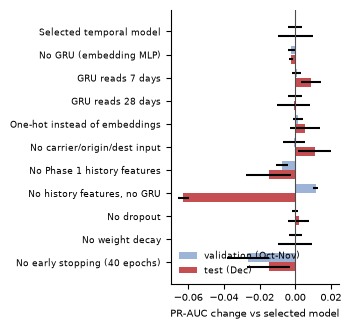

In [7]:
fig, ax = plt.subplots(figsize=(3.5, 3.3))
ypos = np.arange(len(summary))[::-1]
ax.barh(ypos + 0.2, summary["val_change"], 0.38, xerr=summary["val_std"], color="#9DB4D6", label="validation (Oct-Nov)")
ax.barh(ypos - 0.2, summary["test_change"], 0.38, xerr=summary["test_std"], color="#C44E52", label="test (Dec)")
ax.axvline(0, color="0.3", lw=0.8)
ax.set_yticks(ypos, summary.index, fontsize=6.5)
ax.set_xlabel("PR-AUC change vs selected model")
ax.legend(frameon=False, fontsize=6.5, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ablations.pdf")
plt.show()